# 04 — Decide on a retention pilot

**Decision:** fund a randomized pilot with a control group, not a rollout. Contacting the 20% of customers the model ranks highest reaches 61% of those who later left — three times a random campaign — and the campaign pays for itself if one contacted churner in thirty-one is retained. No retention effect has ever been measured on this data, so the size of the prize is an assumption, not a forecast.

**Inputs:** training profiles from 02, frozen test results and assumptions from 03, its post hoc validation views, and the independent review in `reports/review.md`. **Transformations:** presentation and scenario arithmetic only. **Outputs:** decision tables and figures, `business_scenarios.csv`, `economics_ratios.json` and `playbook.csv`. No individual record is accessed, no model is trained and no strategy is selected after reading the test results.

All amounts are illustrative US dollars. The educational definition of `Exited` is documented in 01 through its match with the [Microsoft Learn example](https://learn.microsoft.com/en-us/fabric/data-science/customer-churn); provenance, licensing and chronology are not certified, and the currency of the file's balances is unknown. The study covers only the 10,000 supplied customers.

In [1]:
from pathlib import Path
import json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown
ROOT = Path.cwd() if (Path.cwd() / 'brief.md').exists() else Path.cwd().parent
assert (ROOT / 'brief.md').exists(), 'Run from the project root or notebooks/'
sys.path.insert(0, str(ROOT / 'src'))
from presentation import display, en
SEED = 42
OUT = ROOT / 'data/results'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False, 'text.parse_math': False})
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()

In [2]:
assert (ROOT/'reports/review.md').exists()
freeze=json.loads((OUT/'frozen_protocol.json').read_text())
result=json.loads((OUT/'test_evaluation.json').read_text())
assert result['freeze_sha256']==sha(OUT/'frozen_protocol.json')
segments=pd.read_csv(OUT/'segments_train.csv')
eda=json.loads((OUT/'eda_summary.json').read_text())
assert eda['source_split_sha256']==freeze['split_sha256']
assert result['selected_model']==freeze['selected_model']
# Business views produced by 02 and 03; read, never recomputed here.
profiles=pd.read_csv(OUT/'profiles_train.csv')
age_fine=pd.read_csv(OUT/'age_bands_train.csv')
context=json.loads((OUT/'business_context_train.json').read_text())
explanation=json.loads((OUT/'model_explanation.json').read_text())
bench=pd.read_csv(OUT/'targeting_rules_validation.csv')
curve=pd.read_csv(OUT/'gain_curve_validation.csv')
strategy=pd.DataFrame(result['strategies'])
eco=freeze['economics']
chosen=result['metrics'][result['selected_model']]
ci=result['selected_bootstrap_ic95']
q_breakeven=eco['cost_eur']*chosen['contacts']/(eco['margin_eur']*chosen['departs_contactes'])
kpi=pd.DataFrame([
 {'Indicateur':'Churners reached by contacting 20% of customers','Valeur (test)':f"{chosen['rappel_budget']:.0%} ({chosen['departs_contactes']} of {result['positifs_test']})"},
 {'Indicateur':'Efficiency versus a random campaign','Valeur (test)':f"×{chosen['lift_budget']:.1f}"},
 {'Indicateur':'Efficiency versus the frozen business rule','Valeur (test)':f"+{chosen['departs_contactes']/int(strategy.set_index('strategie').loc['Métier','departs_contactes'])-1:.0%} churners reached"},
 {'Indicateur':'Retention rate needed to break even','Valeur (test)':f"{q_breakeven:.1%} of contacted churners"},
]).set_index('Indicateur')
display(kpi.style)
display(Markdown(f"""## What the study establishes

Among **{result['n_test']:,} test customers** carrying **{result['positifs_test']} churn labels**, the model selected on validation is **{en(result['selected_model'])}**. Its ROC-AUC is **{chosen['roc_auc']:.3f}** (95% bootstrap CI {ci['roc_auc']['bas']:.3f}–{ci['roc_auc']['haut']:.3f}) and its average precision **{chosen['average_precision']:.3f}**, against a test prevalence of **{chosen['prevalence']:.1%}**; Brier is **{chosen['brier']:.3f}**.

At a capacity of **{chosen['contacts']} contacts**, predictive targeting reaches **{chosen['departs_contactes']} churners**: precision **{chosen['precision_budget']:.1%}** (bootstrap {ci['precision_budget']['bas']:.1%}–{ci['precision_budget']['haut']:.1%}), recall **{chosen['rappel_budget']:.1%}**, lift **{chosen['lift_budget']:.2f}**.

**What this study can and cannot tell you.** It ranks churn risk on undated retrospective records, and that ranking is measured. It does not measure whether any offer retains anyone: the label records a departure, not a response, and no customer in this file was ever contacted. The split is random rather than chronological, feature timing before departure is unverified, and the churn definition is an educational convention. Every dollar figure below follows from assumptions fixed in 03, not from a campaign. These limits apply to the whole notebook and are not repeated section by section; the full list closes the report.
"""))

,Valeur (test)
Indicateur,
Churners reached by contacting 20% of customers,61% (248 of 407)
Efficiency versus a random campaign,×3.0
Efficiency versus the frozen business rule,+47% churners reached
Retention rate needed to break even,3.2% of contacted churners


## What the study establishes

Among **2,000 test customers** carrying **407 churn labels**, the model selected on validation is **Random forest (sigmoid)**. Its ROC-AUC is **0.857** (95% bootstrap CI 0.835–0.877) and its average precision **0.685**, against a test prevalence of **20.3%**; Brier is **0.105**.

At a capacity of **400 contacts**, predictive targeting reaches **248 churners**: precision **62.0%** (bootstrap 56.0%–67.2%), recall **60.9%**, lift **3.05**.

**What this study can and cannot tell you.** It ranks churn risk on undated retrospective records, and that ranking is measured. It does not measure whether any offer retains anyone: the label records a departure, not a response, and no customer in this file was ever contacted. The split is random rather than chronological, feature timing before departure is unverified, and the churn definition is an educational convention. Every dollar figure below follows from assumptions fixed in 03, not from a campaign. These limits apply to the whole notebook and are not repeated section by section; the full list closes the report.


## Who leaves, and what is at stake

The profiles below come from the **training** aggregates of 02; nothing is searched for on the test set. They overlap, so their shares of departures do not add up. Proportions are retrospective associations with exploratory 95% Wilson intervals, unadjusted for multiple comparisons, and they are not annual rates.

Two columns matter for a decision that variable-by-variable rates do not provide: the **share of all departures** a profile carries, and its **average balance**. A 100% churn proportion measured on 39 customers is not where a retention budget should go.

Leavers hold 24.2% of training balances while making up 20.4% of customers (mean balance 90,344 against 72,524).
Age 55–64: 50.1% (n=345); age 65+: 12.1% (n=173).


Group,Training customers,Churn labels,Churn proportion,95% CI lower,95% CI upper,Share of all departures,Mean balance (unknown currency)
"45–64, inactive",555,373,67.2%,63.2%,71.0%,30.5%,"84,418"
"Germany, single product",783,333,42.5%,39.1%,46.0%,27.3%,"119,852"
"Under 45, single product, inactive","1,119",261,23.3%,20.9%,25.9%,21.4%,"100,960"
Three or four products,211,180,85.3%,79.9%,89.5%,14.7%,"77,318"
"Two products, active","1,472",89,6.0%,4.9%,7.4%,7.3%,"51,762"


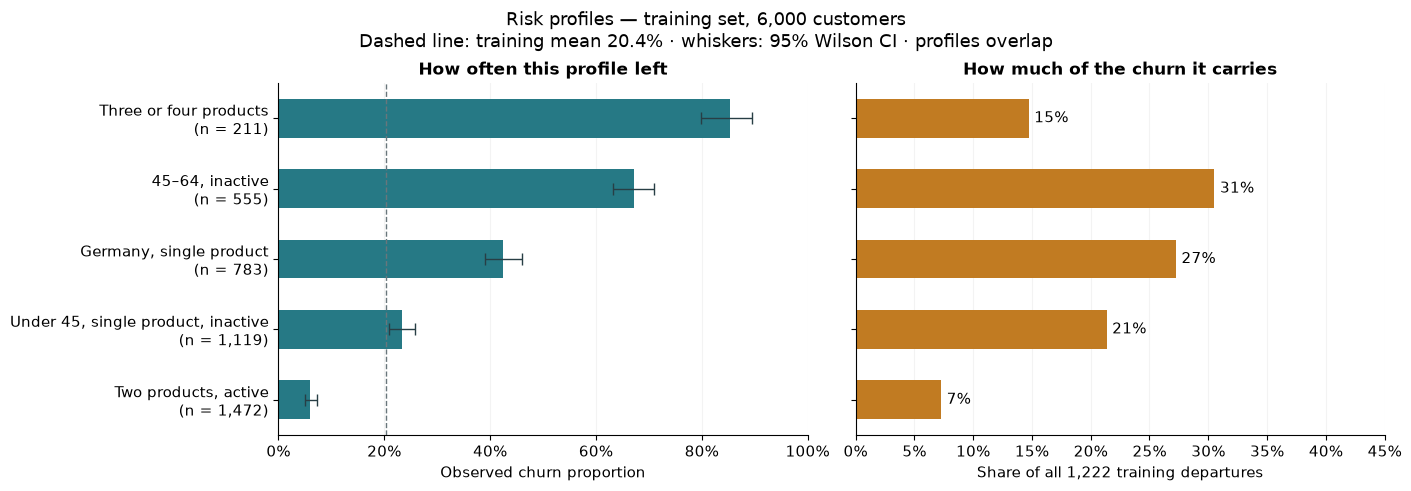

In [3]:
show=profiles.rename(columns={'profil':'Groupe','n':'Clients train','departs':'Labels départ','proportion':'Part départ','part_des_departs':'Share of all departures','solde_moyen':'Mean balance (unknown currency)','ic95_bas':'IC 95 % bas','ic95_haut':'IC 95 % haut'})
display(show[['Groupe','Clients train','Labels départ','Part départ','IC 95 % bas','IC 95 % haut','Share of all departures','Mean balance (unknown currency)']].style.format({'Part départ':'{:.1%}','IC 95 % bas':'{:.1%}','IC 95 % haut':'{:.1%}','Share of all departures':'{:.1%}','Mean balance (unknown currency)':'{:,.0f}','Clients train':'{:,}'}).hide(axis='index'))
fig,axes=plt.subplots(1,2,figsize=(14,4.8),layout='constrained')
order=profiles.sort_values('proportion');positions=np.arange(len(order))
axes[0].barh(positions,order.proportion,height=.55,color='#267985',
 xerr=[order.proportion-order.ic95_bas,order.ic95_haut-order.proportion],capsize=4,error_kw={'ecolor':'#283e45','elinewidth':1})
axes[0].axvline(eda['prevalence_train'],color='#69767b',linestyle='--',linewidth=1)
axes[0].set_yticks(positions,[f'{r.profil}\n(n = {r.n:,})' for r in order.itertuples()])
axes[0].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1,decimals=0))
axes[0].set(xlim=(0,1),xlabel='Observed churn proportion')
axes[0].set_title('How often this profile left',fontsize=12,fontweight='bold')
bars=axes[1].barh(positions,order.part_des_departs,height=.55,color='#c17b22')
axes[1].bar_label(bars,labels=[f'{v:.0%}' for v in order.part_des_departs],padding=4)
axes[1].set_yticks(positions,['']*len(order))
axes[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1,decimals=0))
axes[1].set(xlim=(0,.45),xlabel=f"Share of all {eda['positive_train']:,} training departures")
axes[1].set_title('How much of the churn it carries',fontsize=12,fontweight='bold')
for ax in axes:
 ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)
fig.suptitle('Risk profiles — training set, 6,000 customers\nDashed line: training mean 20.4% · whiskers: 95% Wilson CI · profiles overlap',fontsize=13)
plt.show()
value=context['valeur']
print(f"Leavers hold {value['part_encours_detenue_par_partants']:.1%} of training balances while making up {value['part_clients_partants']:.1%} of customers (mean balance {value['solde_moyen_partants']:,.0f} against {value['solde_moyen_restants']:,.0f}).")
print(f"Age 55–64: {age_fine.set_index('segment').loc['55–64','proportion']:.1%} (n={age_fine.set_index('segment').loc['55–64','n']:,}); age 65+: {age_fine.set_index('segment').loc['65+','proportion']:.1%} (n={age_fine.set_index('segment').loc['65+','n']:,}).")

**What this changes for a retention plan.** The customers at risk are not marginal ones: churners hold 24% of training balances for 20% of customers, and the two profiles with the highest risk also hold the largest average balances. Risk concentrates between 45 and 64 years of age, while customers aged 65 and over are the most stable group in the file — a reversal hidden by any single `55+` figure. The group holding three or four products churns at 85% but carries 15% of departures, so it is a quality-of-sales question rather than a campaign target. None of this attributes a cause: these are associations to investigate with business owners, and section "A playbook" turns them into hypotheses to test rather than actions to launch.

## Compare strategies at the same cost

All four policies were fixed in 03. The business rule ranks customers by `2 × inactive + 1 × age ≥ 45 years`, ties broken with seed 42; predictive targeting uses the calibrated forest selected on validation; random targeting is one fixed draw, not the best of several. Each campaign makes 400 contacts, and no contact is the incremental reference at zero cost and zero gain.

Churn risk does not measure response to an offer. Churners reached are customers who left in this holdout and whom the policy would have contacted — **not departures prevented**. The frozen business rule is deliberately simple, so the table that follows it compares the model with a rule built from the findings of 02, on validation, as a fairer benchmark.

Repeated random targeting would reach an expected 81.4 churners; the fixed draw reaches 85.
Against the EDA-informed rule, the model reaches +36 churners for the same 400 validation contacts, worth US$3,600 per campaign under the reference assumptions.


Strategy,Contacts,Churn labels targeted,Precision,Recall,Lift,Hypothetical cost (USD)
No contact,0,0,—,0.0%,—,0
Random,400,85,21.2%,20.9%,1.04,"4,000"
Business rule,400,169,42.2%,41.5%,2.08,"4,000"
Predictive,400,248,62.0%,60.9%,3.05,"4,000"


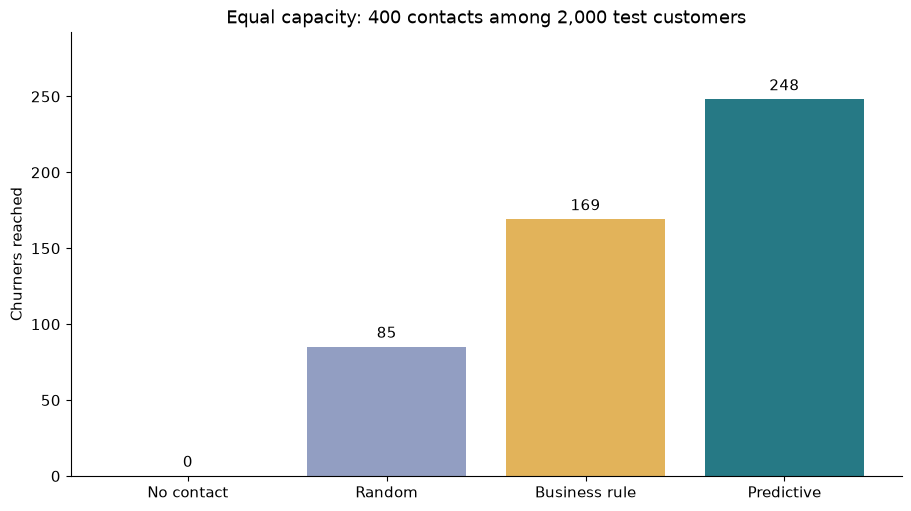

Strategy,Contacts,Churn labels targeted,Precision,Recall,Lift,Mean balance contacted
Random,400,87,21.8%,21.3%,1.07,"79,379"
Business rule,400,176,44.0%,43.1%,2.16,"79,383"
EDA-informed rule,400,226,56.5%,55.4%,2.77,"90,954"
Predictive,400,262,65.5%,64.2%,3.21,"88,803"
Balance-weighted predictive,400,217,54.2%,53.2%,2.66,"126,418"


In [4]:
target_table=strategy[['strategie','contacts','departs_contactes','precision','rappel','lift','cout_scenario_eur']].rename(columns={'strategie':'Stratégie','contacts':'Contacts','departs_contactes':'Labels départ ciblés','precision':'Précision','rappel':'Rappel','lift':'Lift','cout_scenario_eur':'Coût hypothétique (USD)'})
display(target_table.style.format({'Précision':'{:.1%}','Rappel':'{:.1%}','Lift':'{:.2f}','Coût hypothétique (USD)':'{:,.0f}'},na_rep='—').hide(axis='index'))
fig,ax=plt.subplots(layout='constrained')
bars=ax.bar(strategy.strategie.map(en),strategy.departs_contactes,color=['#969696','#929ec2','#e2b35a','#267985'])
ax.bar_label(bars,padding=4)
ax.set(ylabel='Churners reached',title='Equal capacity: 400 contacts among 2,000 test customers',ylim=(0,strategy.departs_contactes.max()*1.18))
plt.show()
print(f"Repeated random targeting would reach an expected {result['random_expected_departures']:.1f} churners; the fixed draw reaches {int(strategy.loc[strategy.strategie.eq('Aléatoire'),'departs_contactes'].iloc[0])}.")
# Fairer benchmark, computed on validation in 03 and declared post hoc.
fair=bench.rename(columns={'strategie':'Stratégie','contacts':'Contacts','departs_contactes':'Labels départ ciblés','precision':'Précision','rappel':'Rappel','lift':'Lift','solde_moyen_contactes':'Mean balance contacted'})
fair['Stratégie']=fair['Stratégie'].map(en)
display(fair.style.format({'Précision':'{:.1%}','Rappel':'{:.1%}','Lift':'{:.2f}','Mean balance contacted':'{:,.0f}'}).hide(axis='index'))
advance=explanation['avance_sur_regle_eda']
print(f"Against the EDA-informed rule, the model reaches +{advance['departs']} churners for the same 400 validation contacts, worth US${advance['gain_scenario_usd']:,.0f} per campaign under the reference assumptions.")

## Economic scenarios: quantify conditions, not measured ROI

All monetary values below are **illustrative US-dollar assumptions** using the numeric scenarios frozen in 03. None is supplied by campaign data. USD is the scenario's unit in this edition; file balances, whose currency is unknown, are not converted.

| Reference assumption | Value and convention |
|---|---|
| Economic horizon | H = 12 months, hypothetical; label horizon unknown |
| Contact | US\$2 per contacted customer |
| Offer | US\$8 paid to every contact, whether they stay or leave |
| Total cost | US\$10 per contact; US\$4,000 for 400 contacts |
| Net margin preserved | US\$500 per departure prevented over H, excluding campaign costs |
| Effect q | 20% of potential departures prevented among contacted customers |
| Eligibility and reachability | Assumed equal and complete |

For each policy: **simulated net gain = q × margin × targeted departure labels − cost × contacts**. Numbers of prevented departures are fractional expectations under assumptions, not observations. The supplied label is assumed to represent departure without a new campaign over H, with no effect on other customers and no interference. This transfer is unverified. No specific offer has been compared: an assumed uniform US\$8 offer does not establish its commercial relevance.

Fixed costs, implementation costs, long-term effects and opportunity costs are unspecified. This scenario is not a complete investment case. Margin must be measured as net contribution, never replaced by balance.


In [5]:
scenarios=[]
for q in eco['effects']:
 for margin in eco['margins']:
  for cost in eco['costs']:
   for r in strategy.itertuples():
    scenarios.append({'strategie':r.strategie,'q':q,'marge_eur':margin,'cout_par_contact_eur':cost,'contacts':r.contacts,'labels_depart_cibles':r.departs_contactes,'departs_evites_attendus_scenario':q*r.departs_contactes,'budget_scenario_eur':cost*r.contacts,'gain_net_scenario_eur':q*margin*r.departs_contactes-cost*r.contacts})
scenarios=pd.DataFrame(scenarios)
reference=scenarios[(scenarios.q==eco['q']) & (scenarios.marge_eur==eco['margin_eur']) & (scenarios.cout_par_contact_eur==eco['cost_eur'])].copy()
# Check against the frozen scenario without accessing customer records.
pd.testing.assert_series_equal(reference.set_index('strategie').gain_net_scenario_eur.sort_index(),strategy.set_index('strategie').gain_net_scenario_eur.sort_index(),check_names=False,check_dtype=False)
reference['q_point_mort']=np.where(reference.labels_depart_cibles>0,reference.budget_scenario_eur/(reference.marge_eur*reference.labels_depart_cibles),np.nan)
display(reference[['strategie','contacts','labels_depart_cibles','departs_evites_attendus_scenario','budget_scenario_eur','gain_net_scenario_eur','q_point_mort']].rename(columns={'strategie':'Stratégie','contacts':'Contacts','labels_depart_cibles':'Labels ciblés','departs_evites_attendus_scenario':'Départs évités supposés','budget_scenario_eur':'Coût scénario (USD)','gain_net_scenario_eur':'Gain net scénario (USD)','q_point_mort':'q au point mort'}).style.format({'Départs évités supposés':'{:.1f}','Coût scénario (USD)':'{:,.0f}','Gain net scénario (USD)':'{:,.0f}','q au point mort':'{:.1%}'},na_rep='—'))
scenarios.to_csv(OUT/'business_scenarios.csv',index=False)

,Strategy,Contacts,Labels targeted,Assumed departures prevented,Scenario cost (USD),Scenario net gain (USD),Break-even q
88,No contact,0,0,0.0,0,0,—
89,Random,400,85,17.0,"4,000","4,500",9.4%
90,Business rule,400,169,33.8,"4,000","12,900",4.7%
91,Predictive,400,248,49.6,"4,000","20,800",3.2%


### Why risk and gain can have the same ranking

For a customer with risk p, hypothetical expected incremental gain is **p × q × M − c**. If q and M are positive and identical across customers, cost c is identical, and the number of contacts is fixed, maximizing the sum of risks maximizes this expectation. Individual break-even would be p > c/(qM), or 10% under the reference scenario; this does not establish that a 20% quota is optimal — the section "How many customers should be contacted" draws the consequence on validation. Well-calibrated risk estimates are needed to interpret this expectation in US dollars.

At q=0, every 400-contact campaign loses its cost, so no contact is preferable. If offer response, margin, reachability or cost varies across customers, risk ranking may stop maximizing gain. A high-risk customer may be impossible to retain. The pilot must measure incremental effects. Randomized data can later support response comparisons or uplift modeling.

### Frozen sensitivity analysis, without selecting a new strategy

The q, margin and cost grid is the one frozen in 03. Capacity remains 400 contacts, so the budget varies with cost (US\$2,000, US\$4,000 or US\$8,000). Within each scenario, campaigns have identical budgets. This sensitivity analysis does not reoptimize models, quotas or segments on the test set.

Strategy,No contact,Random,Business rule,Predictive
Assumed fraction of departures prevented q,,,,
0%,US$0,"US$-4,000","US$-4,000","US$-4,000"
10%,US$0,US$250,"US$4,450","US$8,400"
20%,US$0,"US$4,500","US$12,900","US$20,800"
40%,US$0,"US$13,000","US$29,800","US$45,600"


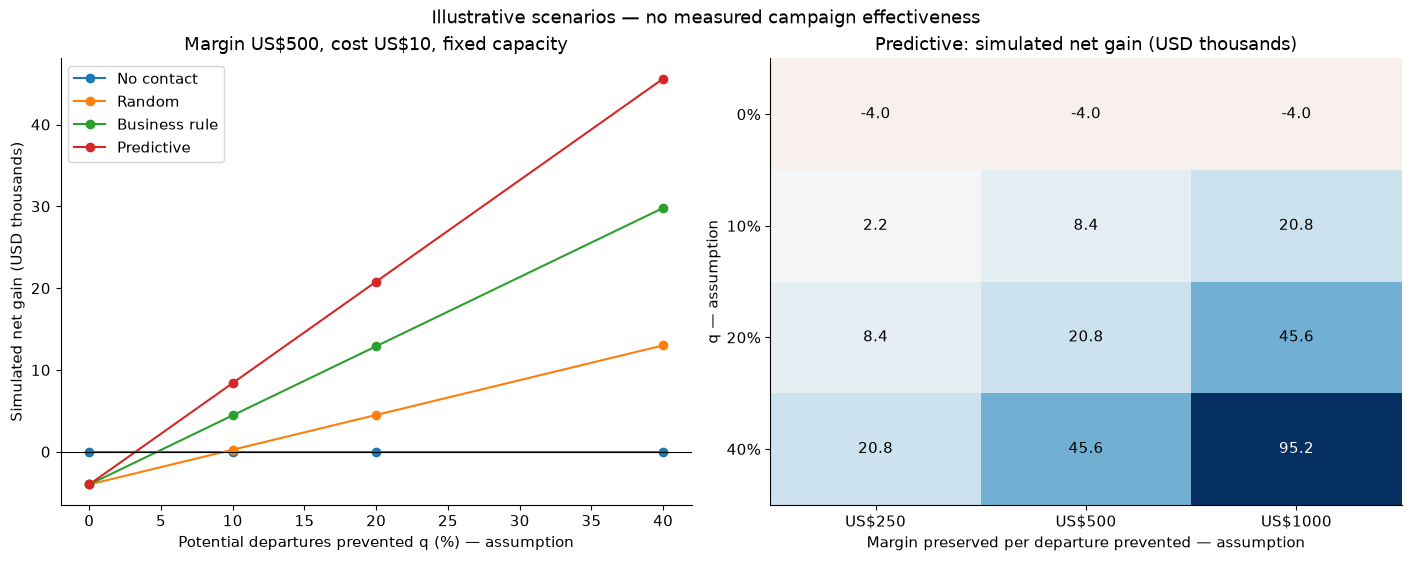

Under the reference scenario, predictive targeting yields **US\$20,800 in simulated net gain**, versus **US\$12,900** for the business rule, **US\$4,500** for random targeting and **US\$0** without a campaign. These are algebraic consequences of q=20%, M=US\$500, c=US\$10 and targeted labels, **not measured gains or a validated forecast**. If q=0, every campaign loses **US\$4,000**, and no campaign is preferable. Predictive targeting breaks even at approximately **3.2% of potential departures prevented** under these conventions; this is not an estimated effect.


In [6]:
base_sensitivity=scenarios[(scenarios.marge_eur==eco['margin_eur']) & (scenarios.cout_par_contact_eur==eco['cost_eur'])]
table=base_sensitivity.pivot(index='q',columns='strategie',values='gain_net_scenario_eur').reindex(columns=freeze['strategies'])
table.index=[f'{q:.0%}' for q in table.index]
table.index.name='Fraction supposée de départs évités q'
display(table.style.format('US${:,.0f}'))
fig,axes=plt.subplots(1,2,figsize=(14,5.5),layout='constrained')
for name,g in base_sensitivity.groupby('strategie',sort=False):
 axes[0].plot(g.q*100,g.gain_net_scenario_eur/1000,'o-',label=en(name))
axes[0].axhline(0,color='black',linewidth=.8)
axes[0].set(xlabel='Potential departures prevented q (%) — assumption',ylabel='Simulated net gain (USD thousands)',title='Margin US$500, cost US$10, fixed capacity')
axes[0].legend()
grid=scenarios[(scenarios.strategie=='Prédictif') & (scenarios.cout_par_contact_eur==eco['cost_eur'])].pivot(index='q',columns='marge_eur',values='gain_net_scenario_eur')
im=axes[1].imshow(grid/1000,cmap='RdBu',aspect='auto',vmin=-float(grid.to_numpy().max()/1000),vmax=float(grid.to_numpy().max()/1000))
axes[1].set_xticks(range(len(grid.columns)),[f'US${v}' for v in grid.columns])
axes[1].set_yticks(range(len(grid.index)),[f'{q:.0%}' for q in grid.index])
axes[1].set(xlabel='Margin preserved per departure prevented — assumption',ylabel='q — assumption',title='Predictive: simulated net gain (USD thousands)')
for i in range(len(grid)):
 for j in range(len(grid.columns)):
  value=grid.iloc[i,j]/1000
  axes[1].text(j,i,f'{value:.1f}',ha='center',va='center',color='white' if abs(value)>grid.to_numpy().max()/2000 else 'black')
fig.suptitle('Illustrative scenarios — no measured campaign effectiveness')
plt.show()
null=scenarios.query('q == 0')
assert (null.loc[null.contacts>0,'gain_net_scenario_eur']==-null.loc[null.contacts>0,'budget_scenario_eur']).all()
display(Markdown(f"""Under the reference scenario, predictive targeting yields **US\\$20,800 in simulated net gain**, versus **US\\$12,900** for the business rule, **US\\$4,500** for random targeting and **US\\$0** without a campaign. These are algebraic consequences of q=20%, M=US\\$500, c=US\\$10 and targeted labels, **not measured gains or a validated forecast**. If q=0, every campaign loses **US\\$4,000**, and no campaign is preferable. Predictive targeting breaks even at approximately **3.2% of potential departures prevented** under these conventions; this is not an estimated effect.
"""))

## How many customers should be contacted

The 20% quota was fixed as an illustrative capacity, never as an optimum. Under the assumptions frozen in 03, a contact is worth making while the customer's risk exceeds `c / (q × M)` = 10%, and 960 of the 2,000 validation customers exceed it. The curve below, computed on **validation** in 03 and declared post hoc, shows what the quota costs and where the money actually is.

It also answers the objection a finance director will raise: if contacting everyone were nearly as profitable, the model would be worth little.

At q=10%, contacting the whole batch returns US$400 against US$9,100 for the 400 best scores: the weaker the offer works, the more targeting decides the outcome.


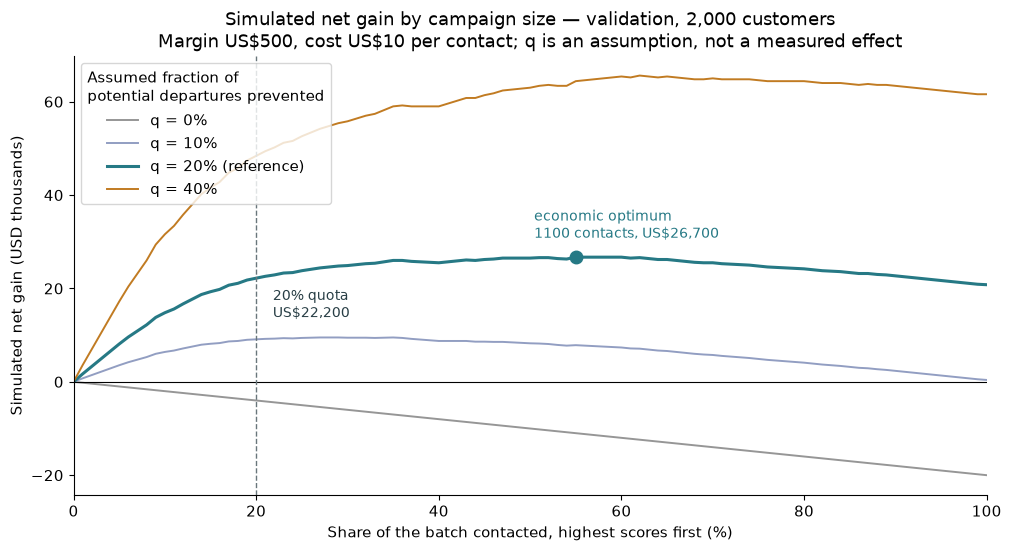

,Value
Reading,
Simulated net gain per contact,US$52
Simulated gain per dollar spent,US$5.2
Gain interval from the precision bootstrap,"US$18,400 to US$22,900"
Contacts with nothing at stake (customers who stayed),"152 of 400, i.e. US$1,216 of offers"


In [7]:
reference_q=eco['q']
eco_capacity=freeze['capacity']
chosen_gain=float(strategy.set_index('strategie').loc['Prédictif','gain_net_scenario_eur'])
fig,ax=plt.subplots(figsize=(10,5.4),layout='constrained')
colors={0:'#969696',.1:'#929ec2',.2:'#267985',.4:'#c17b22'}
for q,g in curve.groupby('q'):
 g=g.sort_values('contacts')
 ax.plot(g.part_contactee*100,g.gain_net_scenario_usd/1000,color=colors.get(q,'#283e45'),
  linewidth=2.2 if q==reference_q else 1.4,label=f'q = {q:.0%}'+(' (reference)' if q==reference_q else ''))
best=pd.DataFrame(explanation['optimum_capacite']).set_index('q').loc[reference_q]
ax.axhline(0,color='black',linewidth=.8)
ax.axvline(100*eco_capacity,color='#69767b',linestyle='--',linewidth=1)
ax.annotate(f"20% quota\nUS${float(curve[(curve.q==reference_q)&(curve.contacts==int(eco_capacity*2000))].gain_net_scenario_usd.iloc[0]):,.0f}",
 (100*eco_capacity,float(curve[(curve.q==reference_q)&(curve.contacts==int(eco_capacity*2000))].gain_net_scenario_usd.iloc[0])/1000),
 textcoords='offset points',xytext=(12,-28),fontsize=10,color='#283e45')
ax.plot(100*best.part_contactee,best.gain_net_scenario_usd/1000,'o',color='#267985',markersize=9)
ax.annotate(f"economic optimum\n{int(best.contacts)} contacts, US${best.gain_net_scenario_usd:,.0f}",
 (100*best.part_contactee,best.gain_net_scenario_usd/1000),textcoords='offset points',xytext=(-30,14),fontsize=10,color='#267985')
ax.set(xlabel='Share of the batch contacted, highest scores first (%)',ylabel='Simulated net gain (USD thousands)',
 title='Simulated net gain by campaign size — validation, 2,000 customers\nMargin US$500, cost US$10 per contact; q is an assumption, not a measured effect',xlim=(0,100))
ax.legend(title='Assumed fraction of\npotential departures prevented')
plt.show()
ratios={'gain_net_scenario_usd':float(chosen_gain),'gain_net_par_contact_usd':float(chosen_gain/chosen['contacts']),
 'gain_par_dollar_depense':float(chosen_gain/(eco['cost_eur']*chosen['contacts'])),
 'intervalle_gain_usd':{'bas':float(eco['q']*eco['margin_eur']*ci['precision_budget']['bas']*chosen['contacts']-eco['cost_eur']*chosen['contacts']),
  'haut':float(eco['q']*eco['margin_eur']*ci['precision_budget']['haut']*chosen['contacts']-eco['cost_eur']*chosen['contacts'])},
 'contacts_sans_enjeu':int(chosen['contacts']-chosen['departs_contactes']),
 'cout_offres_sans_enjeu_usd':float((chosen['contacts']-chosen['departs_contactes'])*eco['offer_cost_eur_all_contacts']),
 'q_point_mort_predictif':float(q_breakeven),
 'seuil_rentabilite_individuel':explanation['seuil_rentabilite_individuel'],
 'clients_validation_au_dessus_du_seuil':explanation['clients_validation_au_dessus_du_seuil'],
 'optimum_capacite_validation':explanation['optimum_capacite'],
 'portee':'arithmétique sur agrégats figés ; validation pour la courbe ; aucune rentabilité mesurée'}
(OUT/'economics_ratios.json').write_text(json.dumps(ratios,ensure_ascii=False,indent=2))
display(pd.DataFrame([
 {'Reading':'Simulated net gain per contact','Value':f"US${ratios['gain_net_par_contact_usd']:,.0f}"},
 {'Reading':'Simulated gain per dollar spent','Value':f"US${ratios['gain_par_dollar_depense']:,.1f}"},
 {'Reading':'Gain interval from the precision bootstrap','Value':f"US${ratios['intervalle_gain_usd']['bas']:,.0f} to US${ratios['intervalle_gain_usd']['haut']:,.0f}"},
 {'Reading':'Contacts with nothing at stake (customers who stayed)','Value':f"{ratios['contacts_sans_enjeu']} of {chosen['contacts']}, i.e. US${ratios['cout_offres_sans_enjeu_usd']:,.0f} of offers"},
]).set_index('Reading').style)
print(f"At q=10%, contacting the whole batch returns US${float(curve[(curve.q==.1)&(curve.contacts==2000)].gain_net_scenario_usd.iloc[0]):,.0f} against US${float(curve[(curve.q==.1)&(curve.contacts==400)].gain_net_scenario_usd.iloc[0]):,.0f} for the 400 best scores: the weaker the offer works, the more targeting decides the outcome.")

**How to read this.** Under the reference assumptions the economic optimum is far larger than the frozen quota, and contacting the entire batch still returns a positive simulated gain — so at q = 20% the model's contribution is budget efficiency rather than feasibility: the same money works harder. The picture reverses as the offer weakens: at q = 10% a blanket campaign is barely above break-even while the 400 best scores still return a clear gain, and at q = 0 every campaign loses exactly its cost.

None of this sizes a real campaign. The curve inherits the assumed margin, cost and effect, and the optimum would move with any of them; capacity should be set with finance from real costs, not read off this chart. It is shown on validation precisely so that no budget is chosen on the test set.

## A playbook: which action for which profile

The frozen scenario assumes one uniform US$8 offer for everyone. That is adequate for a break-even calculation and inadequate as a plan. The table below pairs each profile with the hypothesis that would explain its churn and an action to **test**, not to launch. The signals are measured; the hypotheses and actions are not.

In [8]:
playbook=pd.DataFrame([
 {'profil':'45–64, inactive','hypothese':'Retirement and wealth-planning needs not covered','action_a_tester':'Appointment with a wealth advisor','canal_et_cout':'Advisor; high cost, justified by balances held'},
 {'profil':'Germany, single product','hypothese':'Offer or pricing less competitive in this market','action_a_tester':'Diagnosis first: closure reasons and competitor pricing, then a local offer','canal_et_cout':'Study, then targeted campaign'},
 {'profil':'Three or four products','hypothese':'Unsuitable equipment or pressured selling','action_a_tester':'Sales-quality audit; no additional commercial offer','canal_et_cout':'Quality and compliance, not marketing'},
 {'profil':'Under 45, single product, inactive','hypothese':'Secondary bank, weak relationship','action_a_tester':'Reactivation and a second useful product','canal_et_cout':'Digital; low cost'},
 {'profil':'Two products, active','hypothese':'Healthy relationship','action_a_tester':'Do not contact: every contact costs with nothing at stake','canal_et_cout':'No contact, by design'},
])
playbook=playbook.merge(profiles[['profil','n','proportion','part_des_departs','solde_moyen']],on='profil',how='left')
playbook['signal_train']=[f"{r.proportion:.0%} churn, {r.part_des_departs:.0%} of departures, mean balance {r.solde_moyen:,.0f} (n={r.n:,})" for r in playbook.itertuples()]
display(playbook[['profil','signal_train','hypothese','action_a_tester','canal_et_cout']].fillna('—').rename(columns={'profil':'Groupe','signal_train':'Measured signal (train)','hypothese':'Hypothesis to verify','action_a_tester':'Action to test','canal_et_cout':'Channel and cost'}).style.hide(axis='index'))
playbook.to_csv(OUT/'playbook.csv',index=False)
display(Markdown(f"""Two consequences for the decision. **Cost and margin are not uniform across these rows**, and the rule `p × q × M − c` becomes a real decision tool as soon as they vary: an advisor appointment at US\\$50 can be defended for a customer holding {playbook.set_index('profil').loc['Germany, single product','solde_moyen']:,.0f} in balance and not for a low-balance one. The single-cost scenario frozen in 03 cannot express that, which is a limit of the scenario and not of the data.

**The move from one product to two is the strongest lead, and it is not proof.** Churn falls from {context['produits']['1']['proportion']:.0%} with one product to {context['produits']['2']['proportion']:.0%} with two, but engaged customers may simply be the ones who take a second product. Selling a product to prevent churn is precisely the hypothesis a randomized pilot has to test.
"""))

Group,Measured signal (train),Hypothesis to verify,Action to test,Channel and cost
"45–64, inactive","67% churn, 31% of departures, mean balance 84,418 (n=555)",Retirement and wealth-planning needs not covered,Appointment with a wealth advisor,"Advisor; high cost, justified by balances held"
"Germany, single product","43% churn, 27% of departures, mean balance 119,852 (n=783)",Offer or pricing less competitive in this market,"Diagnosis first: closure reasons and competitor pricing, then a local offer","Study, then targeted campaign"
Three or four products,"85% churn, 15% of departures, mean balance 77,318 (n=211)",Unsuitable equipment or pressured selling,Sales-quality audit; no additional commercial offer,"Quality and compliance, not marketing"
"Under 45, single product, inactive","23% churn, 21% of departures, mean balance 100,960 (n=1,119)","Secondary bank, weak relationship",Reactivation and a second useful product,Digital; low cost
"Two products, active","6% churn, 7% of departures, mean balance 51,762 (n=1,472)",Healthy relationship,Do not contact: every contact costs with nothing at stake,"No contact, by design"


Two consequences for the decision. **Cost and margin are not uniform across these rows**, and the rule `p × q × M − c` becomes a real decision tool as soon as they vary: an advisor appointment at US\$50 can be defended for a customer holding 119,852 in balance and not for a low-balance one. The single-cost scenario frozen in 03 cannot express that, which is a limit of the scenario and not of the data.

**The move from one product to two is the strongest lead, and it is not proof.** Churn falls from 27% with one product to 8% with two, but engaged customers may simply be the ones who take a second product. Selling a product to prevent churn is precisely the hypothesis a randomized pilot has to test.


## The pilot, in one page

| Question a decision-maker will ask | Answer |
|---|---|
| What is being tested? | Two actions against a control, on two score bands: the generic US$8 offer and one playbook action matched to the profile |
| On whom? | Customers with an open account at t0, eligible, not in a concurrent campaign, scored by a temporally validated model. Two bands: the top 20% and a randomized slice below it (scores in the 20–50% range) |
| How many, for how long? | Sample size fixed once the variance of net contribution is known; 12 months of follow-up with a 3-month read on leading indicators |
| What does it cost? | Number of contacts × cost per channel, priced with finance; the US$2 contact and US$8 offer are placeholders |
| What is decided at the end? | Lower bound of the 95% interval for net contribution per assigned customer above US$0 → deploy on the winning band and action. Otherwise → stop, or test another action. A positive effect confined to one band deploys only on that band |

Three departures from the protocol frozen in 03, all aimed at learning more per euro spent: **several arms** rather than one offer, so the pilot learns *which* action works and not only whether contacting works; **a randomized slice below the top 20%**, because the customers most at risk are not necessarily the most responsive, and this is the only way to measure that and to prepare an uplift model later; and **leading indicators at three months** — offer uptake, reactivation, complaints — so the organisation is not blind for a year.

## Recommendations

1. **Data and business owners:** confirm the churn convention, provenance and publication rights; define the eligible population, decision date t0 and horizon. Verify that every feature is available before t0 and that follow-up is complete. A dated cohort and a temporal test are required: the current random split does not demonstrate future performance.
2. **Retention and finance:** document real capacity, contact permissions, contact and offer costs, payment rules and net contribution over the horizon — per channel, since the playbook mixes a digital action with an advisor appointment. The US$8 amount is a scenario, not a recommended offer.
3. **Data team:** keep the frozen policies as research references; monitor drift, calibration and error by group on the new cohort. Note the blind spot measured in 03: the quota misses 146 of 408 validation churners, who are younger and hold the largest balances, and women are slightly over-represented among contacted customers (50.5% against 44.6%) although gender is excluded from the model — a point to raise with compliance rather than to leave implicit.
4. **Decision-maker:** fund the pilot above, and compare the model's measured advantage over a well-built business rule — **+36 churners per 400 contacts, about US$3,600 per campaign** — with the cost of deploying and maintaining a model. A rule may be enough to start; the pilot is what settles whether contacting anyone is worth it at all.

## Remaining limitations

**Retrospective population, no campaign data.** No customer in the file was contacted, so uplift is unmeasurable here and no retention effectiveness is claimed anywhere in this study.

**A conventional label.** The departure convention is inferred from a matching public example; horizon, decision date and censoring are unknown, so no proportion is an annual rate and the 12-month economic horizon is a planning assumption.

**No temporal validation.** The split is a stratified random partition of undated unique customers, and feature chronology is unverified. Measured performance may overstate what a deployment would obtain.

**Assumed economics.** Margin, cost and effect are flat conventions, uniform across customers; the bootstrap intervals cover sampling in the test set conditional on the frozen policy, not uncertainty in the assumptions. The capacity curve and the EDA-rule comparison are post hoc validation views, declared as such, and no budget or policy was chosen on the test set.

**Thin segments and overlapping profiles.** The four-product group holds 39 training customers and the three-product group 172; the five profiles overlap, so their shares of departures do not add up.

## Proposed randomized pilot — detailed protocol

To register **before assignment and outcome observation**, on a new operational population. No pilot results exist.

| Item to prespecify | Concrete proposal |
|---|---|
| Population and score | Customers with an open account at t0 who are eligible and not in concurrent campaigns; features before t0, a dated cohort and a temporally validated score. Choose the final policy before recruitment. |
| Pilot scope | Top 20% of scores and a randomized slice in the 20–50% band; proposed quotas to confirm against real capacity. Conclusions apply only to the bands enrolled. |
| Assignment | Customer-level 1:1 randomization to each action versus a no-new-campaign control; stratify by country and score band; persist assignments and prevent duplicate enrollment. |
| Intervention | One generic offer and one playbook action per profile, both defined before randomization, with recorded payment rules; control receives usual service. Limit other contacts to reduce contamination and interference. |
| Horizon | Proposed H = 12 months after t0, with a prespecified 3-month read on leading indicators, precisely defined departure and complete follow-up in both arms; document censoring and missing data. |
| Primary outcome | Difference in mean net contribution per assigned customer over H, treatment minus control, **by intention to treat**. Include actual contact, offer and service costs and realized margin. Do not substitute balance or gross revenue for contribution. |
| Hypothesis and success | Two-sided test at 5%. Proposed success: the lower bound of the 95% CI for the net effect exceeds US$0 per assigned customer. The US$10 effect is for sample-size planning, not an expected gain; criteria must be ratified before randomization. Do not restrict conclusions to reachable customers or offer acceptors. |
| Secondary outcomes | Cumulative departure, offer uptake, reachability, complaints, opt-outs and costs; define incident stop thresholds with business owners before launch. Segment analyses remain exploratory unless multiple confirmatory tests are prespecified. |
| Sample size and power | 80% power, proposed minimum economically relevant effect US$10. Under balanced allocation and a means approximation: n per arm ≈ 2 × (1.96+0.84)² × σ² / 10². Estimate contribution σ from comparable history or a blinded pilot phase, allow for expected loss to follow-up, then fix n. No reliable sample size is available without this variance; the 2,000 test customers are not a trial. |
| Analysis and stopping | Analyze after complete follow-up, with no opportunistic stopping at significance. Adjust estimates for randomization strata, use intervals robust to margin distributions, and specify missing-data treatment and sensitivity analysis before unblinding. |

This pilot identifies each intervention's effect **within the bands enrolled**. Alone it cannot establish that the score is the best economic policy across the whole customer base; a later randomized comparison of policies would be needed to generalize.

**Traceability:** quality and protocol → 01; profiles and intervals → 02; model selection, metrics, explanation, rules and frozen assumptions → 03; derived scenarios, playbook and proposed protocol → 04. Independent reviews remain in `reports/review.md`.